# Which features predict survival on the Titanic?

The original exploratory notebook contains around 25 plots. This report keeps six, each tied to one feature-selection decision. All figures use the 891 passengers in the training set, the only data with survival labels. Bars show survival rates with 95% confidence intervals; the dashed line marks the overall rate of 38%.

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

from titanic import data, feature, model, plot_utils

TRAIN_PATH = "data/train.csv"
FIG_DIR = "figures"

In [10]:
# Load the training data (only it has the Survived label) and add engineered features
raw_df = data.load_data(TRAIN_PATH)
df = feature.add_family_size(raw_df)
df = feature.add_family_type(df)
df = feature.add_name_features(df)
df = feature.add_grouped_titles(df)
df = feature.add_age_group(df)

## 1. Data quality: what can we use at all?

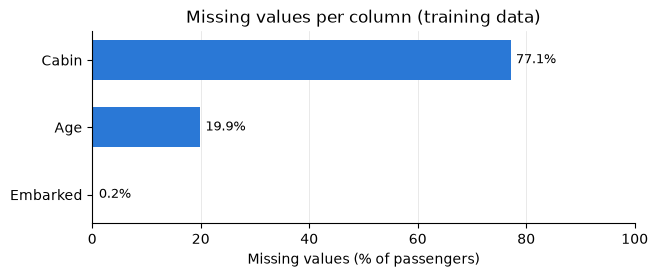

In [11]:
ax = plot_utils.plot_missing(raw_df)
plot_utils.save_figure(ax, "01_missing_values", FIG_DIR)
plt.show()

Cabin is missing for 77% of passengers and is recorded mainly for first class (81% of first-class passengers, 2% of third), so it largely duplicates passenger class. We drop it. Age is missing for 20%: too many to discard, so we keep it and treat missing values as a separate group (Figure 4). The two missing Embarked values are filled with the most frequent port.

## 2. Sex and passenger class

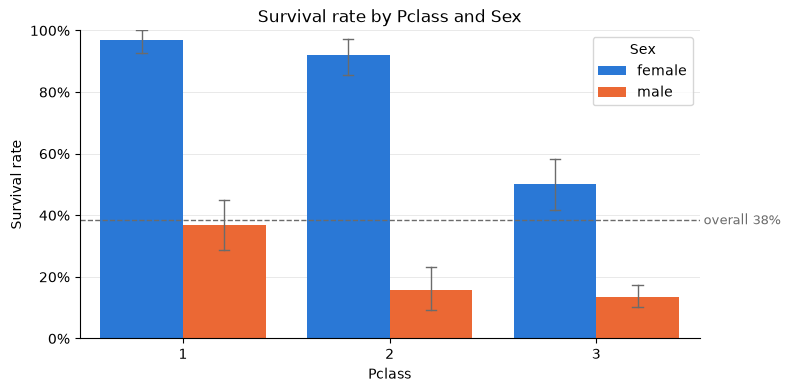

In [12]:
ax = plot_utils.plot_survival_rate(df, column="Pclass", hue="Sex")
plot_utils.save_figure(ax, "02_survival_sex_pclass", FIG_DIR)
plt.show()

Sex is the strongest single signal: women survive at 97%, 92% and 50% across the three classes, men at 37%, 16% and 14%. Class matters within each sex, far more for women, so the features interact. We keep both; a tree-based model can capture the interaction without an explicit combined feature.

## 3. Title

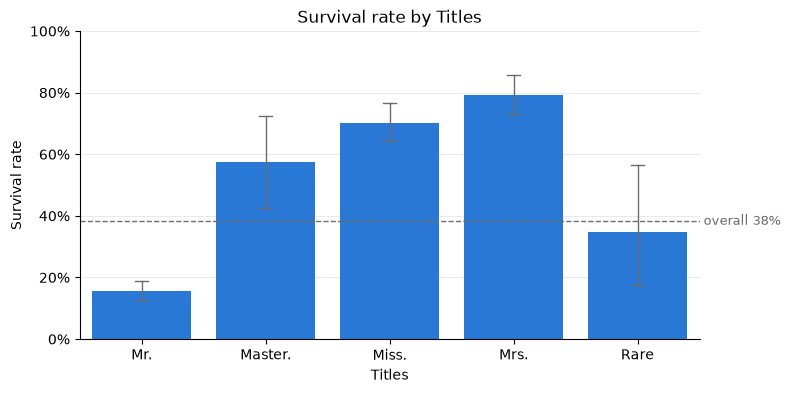

In [13]:
ax = plot_utils.plot_survival_rate(
    df, column="Titles", order=["Mr.", "Master.", "Miss.", "Mrs.", "Rare"]
)
plot_utils.save_figure(ax, "03_survival_title", FIG_DIR)
plt.show()

Title adds what Sex cannot: boys (*Master.*) survive at 57%, adult men (*Mr.*) at only 16%. *Miss.* and *Mrs.* differ little. We keep the grouped title and drop the raw name. Rare titles cover only 23 passengers, as the wide interval shows.

## 4. Age

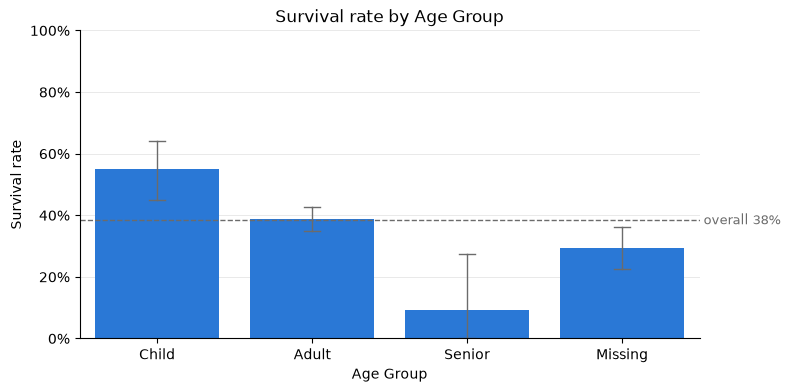

In [14]:
ax = plot_utils.plot_survival_rate(
    df, column="Age Group", order=["Child", "Adult", "Senior", "Missing"]
)
plot_utils.save_figure(ax, "04_survival_age_group", FIG_DIR)
plt.show()

Children (16 or younger) survive at 55%, adults at 39% and the eleven passengers over 64 at 9%. Passengers without a recorded age survive less often (29%), so missingness is itself informative. The original Age Interval feature grouped missing ages with children, which lowered the children's rate to 39% and hid this effect.

## 5. Family size

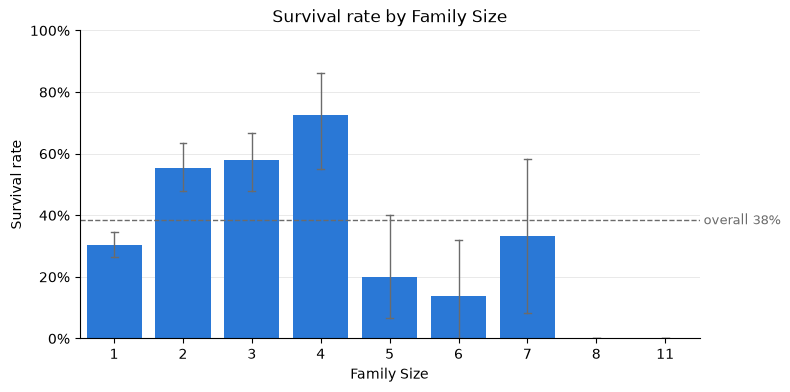

In [15]:
ax = plot_utils.plot_survival_rate(df, column="Family Size")
plot_utils.save_figure(ax, "05_survival_family_size", FIG_DIR)
plt.show()

Survival follows an inverted U: 30% for passengers travelling alone, 55–72% for families of two to four, and at most a third for larger families. Because the relationship is not linear, we combine SibSp and Parch into Family Type (Single, Small, Large) instead of using them separately.

## 6. Does a model confirm the selection?

Baseline (Sex, Pclass) accuracy: 76.5%
Selected features accuracy:      82.7%


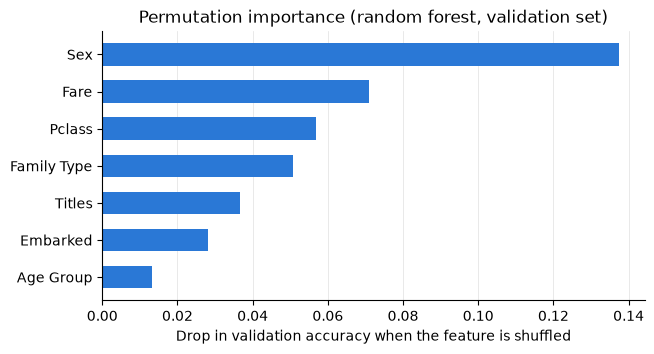

In [16]:
# Encode the selected categorical features as integers for the random forest
selected = ["Sex", "Pclass", "Titles", "Age Group", "Family Type", "Fare", "Embarked"]
model_df = feature.encode_sex(df)
model_df["Embarked"] = model_df["Embarked"].fillna(model_df["Embarked"].mode()[0])
for column in ["Titles", "Age Group", "Family Type", "Embarked"]:
    model_df[column] = model_df[column].astype("category").cat.codes

train, valid = model.split_data(model_df)
clf = model.train_model(train[selected], train["Survived"])
baseline = model.train_model(train[["Sex", "Pclass"]], train["Survived"])

print(f"Baseline (Sex, Pclass) accuracy: {baseline.score(valid[['Sex', 'Pclass']], valid['Survived']):.1%}")
print(f"Selected features accuracy:      {clf.score(valid[selected], valid['Survived']):.1%}")

importances = model.permutation_importances(clf, valid[selected], valid["Survived"])
ax = plot_utils.plot_feature_importance(importances)
plot_utils.save_figure(ax, "06_feature_importance", FIG_DIR)
plt.show()

To check these choices, we trained a random forest on them. Validation accuracy rises from 76.5% (Sex and Pclass only) to 82.7%, based on a single 80/20 split. Permutation importance ranks Sex first, followed by Fare, Pclass and Family Type. Embarked and Age Group contribute least: Embarked largely reflects class, and Title already identifies boys. Because correlated features share credit, a low score means a feature adds little on top of the others, not that it is unrelated to survival.

## Conclusion

Cabin is missing for 77% of passengers and is recorded mainly for first class (81% of first-class passengers, 2% of third), so it largely duplicates passenger class. We drop it. Age is missing for 20%: too many to discard, so we keep it and treat missing values as a separate group (Figure 4). The two missing Embarked values are filled with the most frequent port.